In [2]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats


## Working with perfectly Linear Dataset

In [5]:
from sklearn.datasets import make_blobs

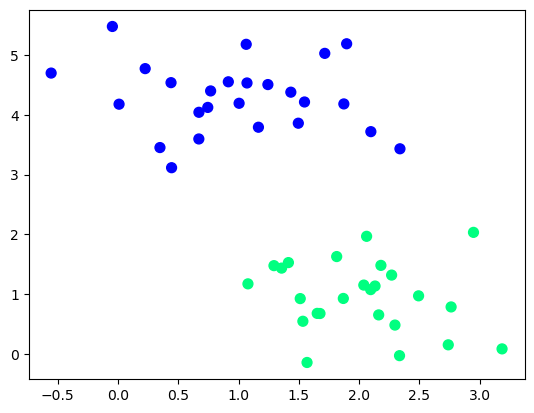

In [11]:
X, y = make_blobs(n_samples=50, centers=2, random_state=0,
                 cluster_std=0.6)
plt.scatter(X[:,0], X[:,1], c=y, s =50, cmap='winter')

In [13]:
from sklearn.svm import SVC #Support Vector Classifier
model = SVC(kernel='linear', C=1)
model.fit(X,y)

SVC(C=1, kernel='linear')

In [14]:
SVC(C=1, cache_size=200, class_weight=None, coef0=0.0, 
   decision_function_shape='ovr', degree=3, gamma='auto deprecated',
   kernel='linear', max_iter=-1, probability=False, random_state=None,
   shrinking=True, tol=0.001, verbose=False)

SVC(C=1, gamma='auto deprecated', kernel='linear')

In [15]:
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y,x)
    xy = np.vstack(X.ravel(), Y.ravel()).T
    P = model.decision_function(xy).reshape(X.shape)
    
    ax.countour(X,Y,P, color='k', levels=[-1,0,1], alpha=0.5,
               linestyles=['--', '-', '--'])
    
    if plot_support:
        ax.scatter(model.support_vectors_[:,0],
                  model.support_vectors_[:,1], 
                  s=300, linewidth=1, facecolors='none');
    
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    
    